# Project 11：心脏病早期风险预测与现场交互

基于 **UCI Heart Disease（Cleveland）** 数据集和 `P11_01.pdf` 的分析方案，本 Notebook 完成：

1. 数据读取、缺失值处理与探索性数据分析（EDA）；
2. 逻辑回归、决策树、随机森林三种分类器的训练与比较；
3. Accuracy、Sensitivity、Specificity、F1、ROC-AUC 和交叉验证评估；
4. 特征重要性与逻辑回归系数解释；
5. **动态输入 13 项医学指标，选择模型与阈值，现场输出风险概率和分类结果。**

> 运行方式：保持本文件与 `heart+disease` 文件夹的相对位置不变，在 Jupyter 中选择 **Kernel → Restart & Run All**。最后一部分为交互预测面板。
>
> **免责声明：** 本模型仅用于数据科学教学，不能用于临床诊断或替代专业医疗建议。

## 1. 环境准备

所需包：`numpy`、`pandas`、`matplotlib`、`seaborn`、`scikit-learn`、`ipywidgets`。如本机缺少依赖，可在终端执行：

```bash
python -m pip install numpy pandas matplotlib seaborn scikit-learn ipywidgets notebook
```

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)

## 2. 读取数据与缺失值处理

原始文件有 303 行、14 列，其中 `ca` 和 `thal` 含 `?`。按照 PDF 的完整病例分析方案，将 `?` 读为缺失值并删除含缺失值的 6 行，最终使用 **297 条记录**。目标变量由原始的 0～4 级诊断转换为二分类：0 表示无心脏病，1～4 合并为 1（存在心脏病）。

In [2]:
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]
feature_names = columns[:-1]
continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

candidates = [
    Path.cwd() / "heart+disease" / "processed.cleveland.data",
    Path.cwd() / "processed.cleveland.data",
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("未找到 processed.cleveland.data，请确认 heart+disease 文件夹与本 Notebook 位于同一目录。")

raw = pd.read_csv(DATA_PATH, header=None, names=columns, na_values="?")
missing_summary = pd.DataFrame({
    "缺失数量": raw.isna().sum(),
    "缺失比例(%)": (raw.isna().mean() * 100).round(2)
})
print(f"数据文件：{DATA_PATH.resolve()}")
print(f"原始数据：{raw.shape[0]} 行 × {raw.shape[1]} 列")
display(missing_summary[missing_summary["缺失数量"] > 0])

df = raw.dropna().copy()
df["target"] = (df["target"] > 0).astype(int)
for col in categorical:
    df[col] = df[col].astype(int)

assert df.shape == (297, 14), "清洗后的数据形状与 PDF 不一致"
assert not df.isna().any().any(), "数据中仍有缺失值"
print(f"建模数据：{df.shape[0]} 行 × {df.shape[1]} 列；无缺失值")
display(df.head())

数据文件：D:\kimicode_cash\heart+disease\processed.cleveland.data
原始数据：303 行 × 14 列


,缺失数量,缺失比例(%)
ca,4,1.32
thal,2,0.66


建模数据：297 行 × 14 列；无缺失值


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0,6,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3,3,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2,7,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0,3,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0,3,0


## 3. 探索性数据分析（EDA）

目标类别略有不均衡，因此除 Accuracy 外，还需重点关注 **Sensitivity（患病者被识别出来的比例）** 和 **ROC-AUC**。

类别分布：


,样本数,比例(%)
无心脏病 (0),160,53.9
存在心脏病 (1),137,46.1


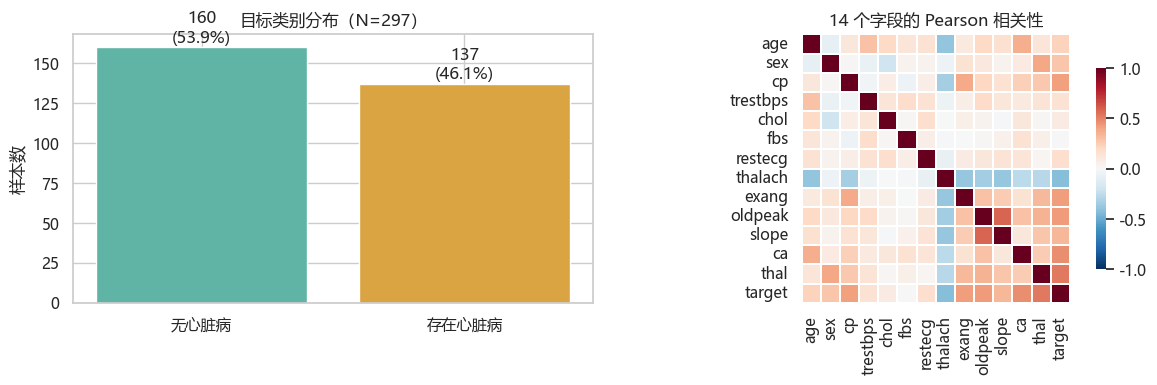

In [3]:
class_counts = df["target"].value_counts().sort_index()
print("类别分布：")
display(pd.DataFrame({
    "样本数": class_counts,
    "比例(%)": (class_counts / len(df) * 100).round(1)
}).rename(index={0: "无心脏病 (0)", 1: "存在心脏病 (1)"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["无心脏病", "存在心脏病"], class_counts.values, color=["#5FB4A5", "#D9A441"])
axes[0].set_title("目标类别分布（N=297）")
axes[0].set_ylabel("样本数")
for i, value in enumerate(class_counts.values):
    axes[0].text(i, value + 3, f"{value}\n({value / len(df):.1%})", ha="center")

corr = df.corr()
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.75}, ax=axes[1])
axes[1].set_title("14 个字段的 Pearson 相关性")
plt.tight_layout()
plt.show()

连续变量描述性统计：


,count,mean,std,min,25%,50%,75%,max,median,IQR
age,297.0,54.54,9.05,29.0,48.0,56.0,61.0,77.0,56.0,13.0
trestbps,297.0,131.69,17.76,94.0,120.0,130.0,140.0,200.0,130.0,20.0
chol,297.0,247.35,52.00,126.0,211.0,243.0,276.0,564.0,243.0,65.0
thalach,297.0,149.60,22.94,71.0,133.0,153.0,166.0,202.0,153.0,33.0
oldpeak,297.0,1.06,1.17,0.0,0.0,0.8,1.6,6.2,0.8,1.6


按目标分组的均值：


,age,trestbps,chol,thalach,oldpeak
target,,,,,
无心脏病,52.64,129.18,243.49,158.58,0.60
存在心脏病,56.76,134.64,251.85,139.11,1.59


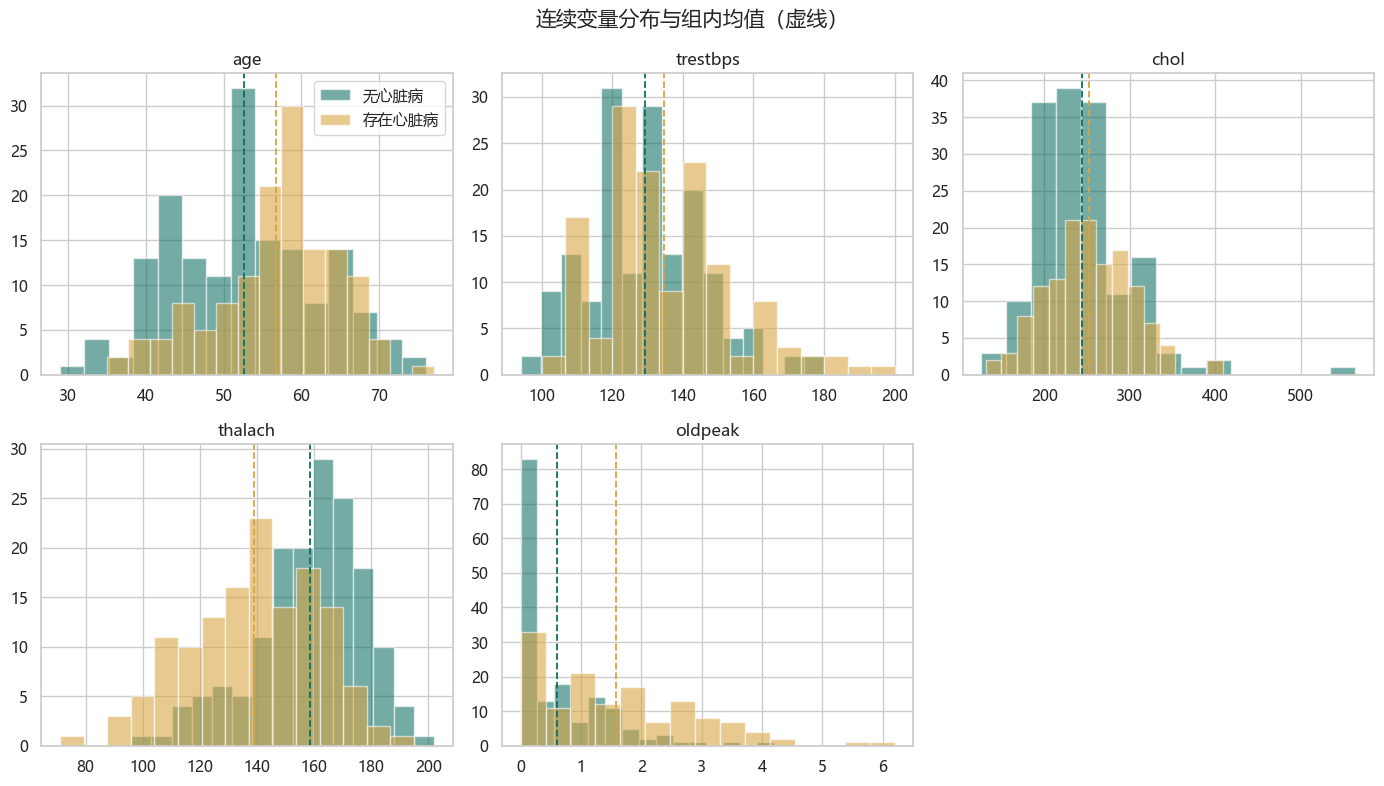

In [4]:
desc = df[continuous].describe().T
desc["median"] = df[continuous].median()
desc["IQR"] = desc["75%"] - desc["25%"]
print("连续变量描述性统计：")
display(desc.round(2))
print("按目标分组的均值：")
display(df.groupby("target")[continuous].mean().rename(index={0: "无心脏病", 1: "存在心脏病"}).round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.ravel(), continuous):
    for target, color, label in [(0, "#0F6E63", "无心脏病"), (1, "#D9A441", "存在心脏病")]:
        values = df.loc[df["target"] == target, col]
        ax.hist(values, bins=15, alpha=0.58, color=color, label=label, edgecolor="white")
        ax.axvline(values.mean(), color=color, linestyle="--", linewidth=1.3)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
axes.ravel()[0].legend()
fig.suptitle("连续变量分布与组内均值（虚线）", fontsize=15)
plt.tight_layout()
plt.show()

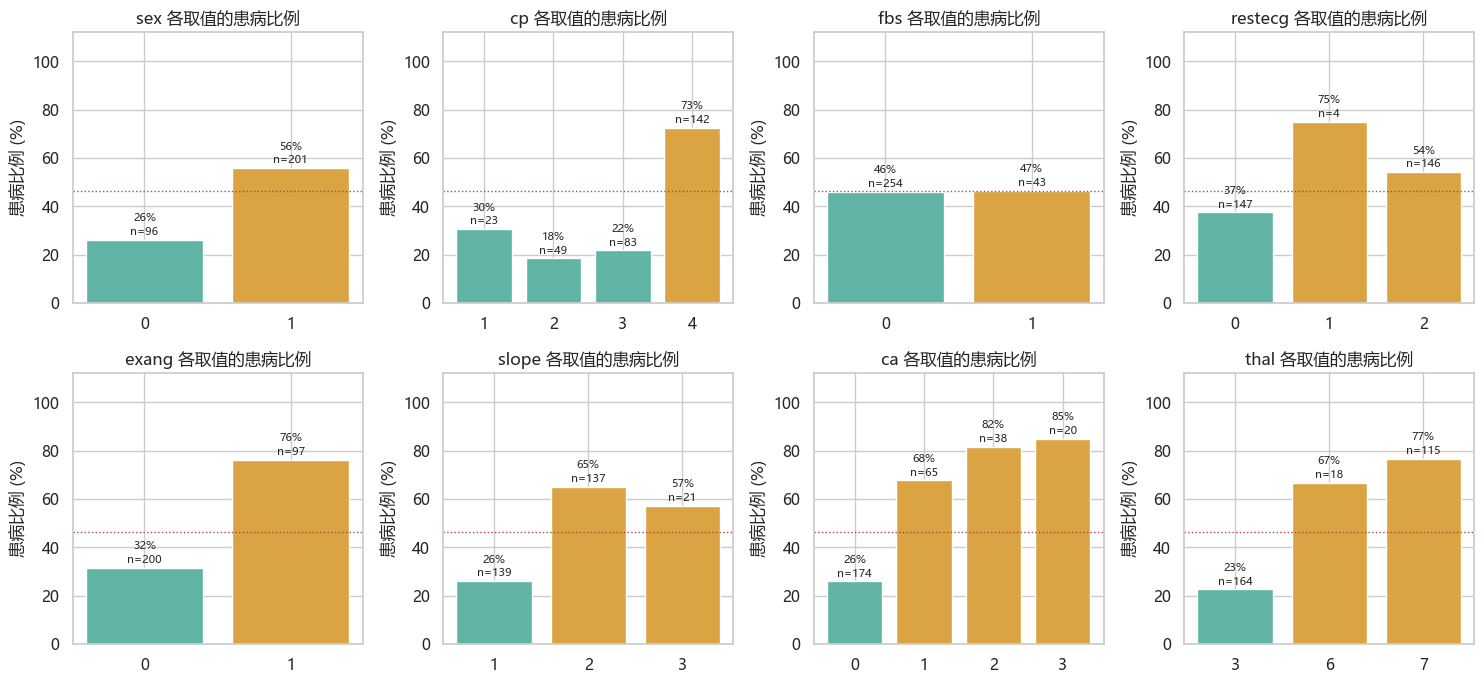

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
base_rate = df["target"].mean()
for ax, col in zip(axes.ravel(), categorical):
    rate = df.groupby(col)["target"].mean()
    counts = df.groupby(col).size()
    colors = ["#D9A441" if r >= base_rate else "#5FB4A5" for r in rate]
    bars = ax.bar(rate.index.astype(str), rate.values * 100, color=colors)
    for bar, r, n in zip(bars, rate, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, r * 100 + 2,
                f"{r:.0%}\nn={n}", ha="center", fontsize=8)
    ax.axhline(base_rate * 100, color="#B0483E", linestyle=":", linewidth=1)
    ax.set_ylim(0, 112)
    ax.set_title(f"{col} 各取值的患病比例")
    ax.set_ylabel("患病比例 (%)")
plt.tight_layout()
plt.show()

## 4. 模型训练与多指标评估

与 PDF 保持一致：按 75%/25% 分层划分训练集和测试集，`random_state=42`。逻辑回归先标准化；决策树最大深度为 4；随机森林使用 300 棵树、最大深度为 5。交叉验证采用 5 折分层交叉验证。

- **Sensitivity / Recall**：在实际患病者中预测为患病的比例，越高意味着漏诊越少。
- **Specificity**：在实际未患病者中预测为未患病的比例。
- **ROC-AUC**：模型对不同阈值下正负样本的排序能力，越大越好。

In [6]:
X = df[feature_names]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

models = {
    "逻辑回归": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "决策树": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "随机森林": RandomForestClassifier(
        n_estimators=300, max_depth=5, random_state=RANDOM_STATE
    ),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
roc_data = {}
confusions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    probability = model.predict_proba(X_test)[:, 1]
    prediction = (probability >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, prediction).ravel()
    results.append({
        "模型": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Sensitivity": recall_score(y_test, prediction),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(y_test, prediction, zero_division=0),
        "F1": f1_score(y_test, prediction),
        "ROC-AUC": roc_auc_score(y_test, probability),
        "5折CV-AUC": cross_val_score(model, X, y, cv=cv, scoring="roc_auc").mean(),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })
    roc_data[name] = roc_curve(y_test, probability)
    confusions[name] = np.array([[tn, fp], [fn, tp]])

metrics_df = pd.DataFrame(results).set_index("模型")
display(metrics_df.round(3))
best_model_name = metrics_df["ROC-AUC"].idxmax()
print(f"测试集 ROC-AUC 最高的模型：{best_model_name}")

,Accuracy,Sensitivity,Specificity,Precision,F1,ROC-AUC,5折CV-AUC,TN,FP,FN,TP
模型,,,,,,,,,,,
逻辑回归,0.853,0.829,0.875,0.853,0.841,0.947,0.894,35,5,6,29
决策树,0.693,0.657,0.725,0.676,0.667,0.736,0.813,29,11,12,23
随机森林,0.827,0.771,0.875,0.844,0.806,0.934,0.898,35,5,8,27


测试集 ROC-AUC 最高的模型：逻辑回归


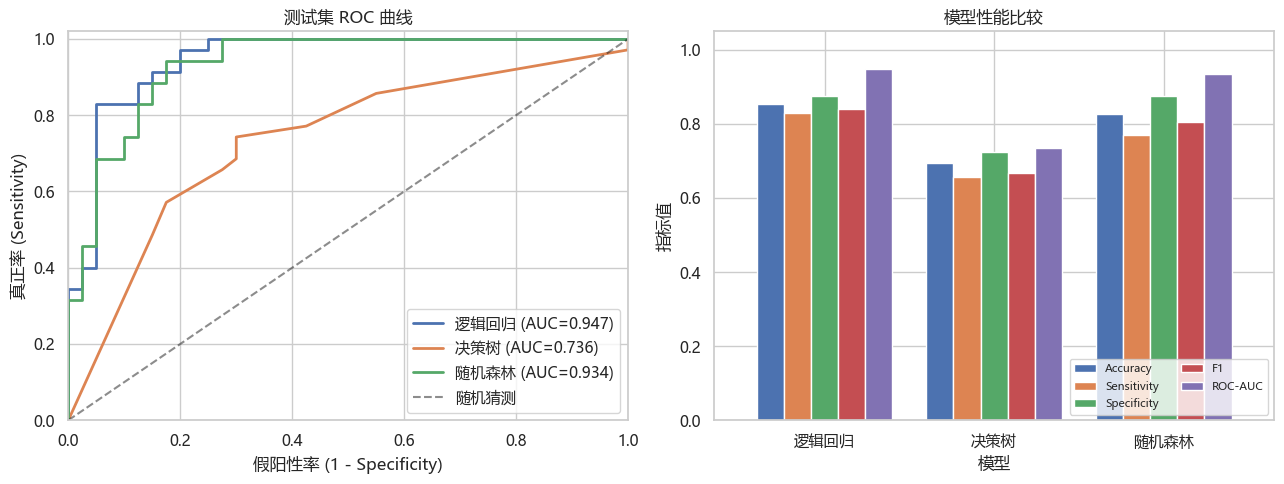

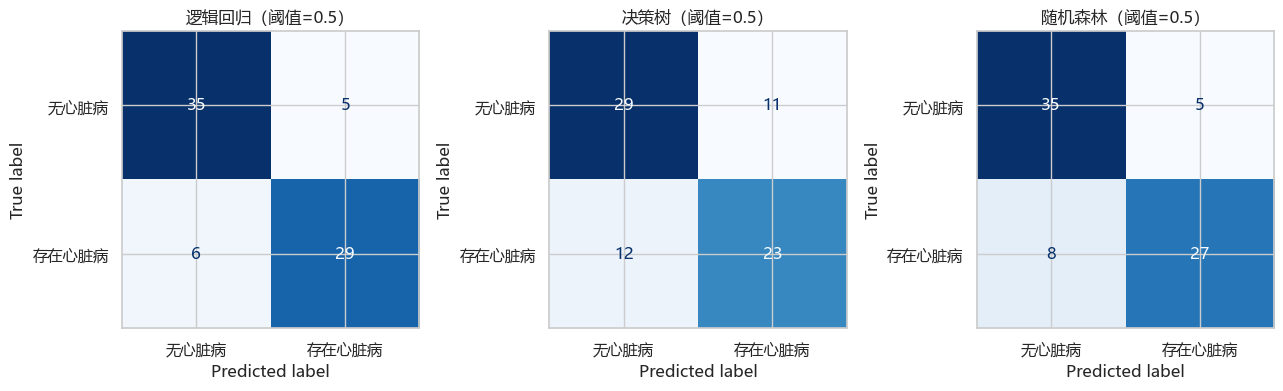

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, (fpr, tpr, _) in roc_data.items():
    axes[0].plot(fpr, tpr, linewidth=2,
                 label=f"{name} (AUC={metrics_df.loc[name, 'ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="随机猜测")
axes[0].set(xlabel="假阳性率 (1 - Specificity)", ylabel="真正率 (Sensitivity)",
            title="测试集 ROC 曲线", xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(loc="lower right")

metric_plot = metrics_df[["Accuracy", "Sensitivity", "Specificity", "F1", "ROC-AUC"]]
metric_plot.plot(kind="bar", ax=axes[1], ylim=(0, 1.05), width=0.8)
axes[1].set_title("模型性能比较")
axes[1].set_ylabel("指标值")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(loc="lower right", fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, matrix) in zip(axes, confusions.items()):
    ConfusionMatrixDisplay(matrix, display_labels=["无心脏病", "存在心脏病"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(f"{name}（阈值=0.5）")
plt.tight_layout()
plt.show()

## 5. 特征重要性与医学解释

以下使用测试集上的 **置换重要性（Permutation Importance）**：随机打乱某个特征后 ROC-AUC 平均下降越多，说明该特征对当前模型越重要。它不表示因果关系。逻辑回归部分同时给出标准化系数方向：正值倾向于提高风险，负值倾向于降低风险。

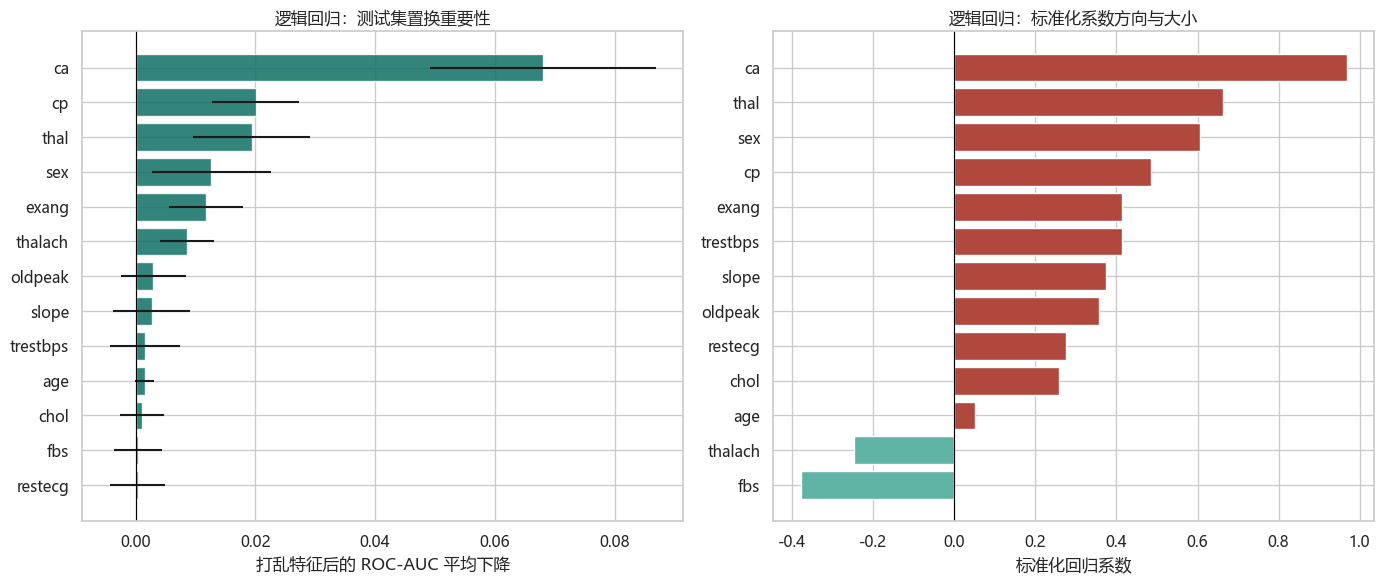

,特征,标准化系数,比值比(每增加1个标准差)
11,ca,0.968,2.633
12,thal,0.664,1.942
1,sex,0.606,1.833
2,cp,0.485,1.625
8,exang,0.415,1.514
3,trestbps,0.413,1.511
10,slope,0.375,1.454
9,oldpeak,0.356,1.428
6,restecg,0.276,1.317
4,chol,0.258,1.294


In [8]:
importance = permutation_importance(
    models[best_model_name], X_test, y_test,
    scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE
)
importance_df = pd.DataFrame({
    "特征": feature_names,
    "AUC平均下降": importance.importances_mean,
    "标准差": importance.importances_std,
}).sort_values("AUC平均下降", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(importance_df["特征"], importance_df["AUC平均下降"],
             xerr=importance_df["标准差"], color="#0F6E63", alpha=0.85)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title(f"{best_model_name}：测试集置换重要性")
axes[0].set_xlabel("打乱特征后的 ROC-AUC 平均下降")

lr = models["逻辑回归"].named_steps["classifier"]
coefficient_df = pd.DataFrame({
    "特征": feature_names,
    "标准化系数": lr.coef_[0],
}).sort_values("标准化系数")
coefficient_df["比值比(每增加1个标准差)"] = np.exp(coefficient_df["标准化系数"])
colors = ["#B0483E" if v > 0 else "#5FB4A5" for v in coefficient_df["标准化系数"]]
axes[1].barh(coefficient_df["特征"], coefficient_df["标准化系数"], color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("逻辑回归：标准化系数方向与大小")
axes[1].set_xlabel("标准化回归系数")
plt.tight_layout()
plt.show()
display(coefficient_df.sort_values("标准化系数", ascending=False).round(3))

## 6. 动态输入新数据并现场预测

在下方直接修改输入项即可，**结果会自动更新**，无需重新运行单元格：

- 可从逻辑回归、决策树、随机森林中切换模型；
- 默认分类阈值为 0.5，可拖动滑块调整；概率 ≥ 阈值时判为高风险（1）；
- 输出包括风险概率、分类结果、概率条和本次输入记录。

字段提示：`cp` 为胸痛类型；`trestbps` 为静息血压；`chol` 为血清胆固醇；`fbs` 为空腹血糖是否大于 120 mg/dl；`restecg` 为静息心电图；`thalach` 为最大心率；`exang` 为运动诱发心绞痛；`oldpeak` 为运动相对静息的 ST 段压低；`slope` 为 ST 段斜率；`ca` 为荧光显影的主要血管数；`thal` 为地中海贫血/铊显像检查分类。

In [10]:
import ipywidgets as widgets
from ipywidgets import interactive_output

widget_layout = widgets.Layout(width="350px")
style = {"description_width": "initial"}

inputs = {
    "age": widgets.IntSlider(value=54, min=18, max=100, step=1,
                             description="年龄 age（岁）", continuous_update=False,
                             layout=widget_layout, style=style),
    "sex": widgets.Dropdown(options=[("女", 0), ("男", 1)], value=1,
                            description="性别 sex", layout=widget_layout, style=style),
    "cp": widgets.Dropdown(options=[("1 典型心绞痛", 1), ("2 非典型心绞痛", 2),
                                    ("3 非心绞痛性疼痛", 3), ("4 无症状", 4)], value=4,
                           description="胸痛类型 cp", layout=widget_layout, style=style),
    "trestbps": widgets.IntText(value=130, description="静息血压 trestbps（mmHg）",
                                layout=widget_layout, style=style),
    "chol": widgets.IntText(value=246, description="胆固醇 chol（mg/dl）",
                            layout=widget_layout, style=style),
    "fbs": widgets.Dropdown(options=[("否（≤120 mg/dl）", 0), ("是（>120 mg/dl）", 1)], value=0,
                            description="空腹血糖 fbs", layout=widget_layout, style=style),
    "restecg": widgets.Dropdown(options=[("0 正常", 0), ("1 ST-T 波异常", 1),
                                         ("2 左心室肥大", 2)], value=0,
                                description="静息心电图 restecg", layout=widget_layout, style=style),
    "thalach": widgets.IntText(value=150, description="最大心率 thalach（次/分）",
                               layout=widget_layout, style=style),
    "exang": widgets.Dropdown(options=[("否", 0), ("是", 1)], value=0,
                              description="运动诱发心绞痛 exang", layout=widget_layout, style=style),
    "oldpeak": widgets.FloatSlider(value=1.0, min=0, max=8, step=0.1,
                                   description="ST 段压低 oldpeak", continuous_update=False,
                                   layout=widget_layout, style=style),
    "slope": widgets.Dropdown(options=[("1 上升", 1), ("2 平坦", 2), ("3 下降", 3)], value=2,
                              description="ST 段斜率 slope", layout=widget_layout, style=style),
    "ca": widgets.Dropdown(options=[0, 1, 2, 3], value=0,
                           description="主要血管数 ca", layout=widget_layout, style=style),
    "thal": widgets.Dropdown(options=[("3 正常", 3), ("6 固定缺陷", 6),
                                      ("7 可逆缺陷", 7)], value=3,
                             description="地中海贫血类型 thal", layout=widget_layout, style=style),
}
model_picker = widgets.Dropdown(options=list(models.keys()), value="逻辑回归",
                                description="预测模型", layout=widget_layout, style=style)
threshold_widget = widgets.FloatSlider(value=0.50, min=0.05, max=0.95, step=0.01,
                                       description="高风险阈值", continuous_update=False,
                                       layout=widget_layout, style=style)


def predict_new_data(model_name, threshold, **values):
    if not 0 < threshold < 1:
        raise ValueError("分类阈值必须在 0 和 1 之间。")
    new_data = pd.DataFrame([values], columns=feature_names)
    probability = float(models[model_name].predict_proba(new_data)[0, 1])
    prediction = int(probability >= threshold)
    return probability, prediction, new_data


def update_prediction(model_name, threshold, **values):
    probability, prediction, new_data = predict_new_data(model_name, threshold, **values)
    label = "高风险（1）" if prediction == 1 else "较低风险（0）"
    color = "#B0483E" if prediction == 1 else "#0F6E63"
    display(HTML(f'''
        <div style="border-left:6px solid {color};padding:10px 14px;margin:6px 0;background:#f6f8f9">
          <div style="font-size:18px"><b>模型分类：{label}</b></div>
          <div>使用模型：<b>{model_name}</b>　预测心脏病概率：<b style="color:{color};font-size:20px">{probability:.1%}</b>　分类阈值：{threshold:.2f}</div>
        </div>
    '''))
    fig, ax = plt.subplots(figsize=(9, 0.8))
    ax.barh([0], [1], color="#E4E9EC", height=0.5)
    ax.barh([0], [probability], color=color, height=0.5)
    ax.axvline(threshold, color="#22333B", linestyle="--", linewidth=1.5)
    ax.text(threshold, 0.38, f"阈值 {threshold:.2f}", ha="center", fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_yticks([])
    ax.set_xlabel("预测心脏病概率")
    for spine in ax.spines.values():
        spine.set_visible(False)
    plt.tight_layout()
    plt.show()
    with pd.option_context("display.max_rows", 20):
        display(new_data.T.rename(columns={0: "本次输入值"}))
    print("提示：概率来自小型公开教学数据集，仅供课程演示，不构成医学诊断。")


controls = {"model_name": model_picker, "threshold": threshold_widget, **inputs}
prediction_output = interactive_output(update_prediction, controls)
input_grid = widgets.GridBox(
    children=list(inputs.values()),
    layout=widgets.Layout(grid_template_columns="repeat(2, 350px)", grid_gap="6px 14px")
)
display(widgets.HTML("<h3>现场预测面板</h3><p>修改任一输入后自动重新预测。</p>"))
display(widgets.HBox([model_picker, threshold_widget]))
display(input_grid)
display(prediction_output)

HTML(value='<h3>现场预测面板</h3><p>修改任一输入后自动重新预测。</p>')

GridBox(children=(IntSlider(value=54, continuous_update=False, description='年龄 age（岁）', layout=Layout(width='3…

Output()

## 7. 结论与使用边界

- 本 Notebook 已复现 PDF 的数据清洗、训练/测试划分和三类模型，并提供多指标比较。
- 现场预测使用上面已训练的模型，输入会经过与训练数据相同的标准化或树模型流程。
- Cleveland 数据仅 297 条完整病例，来源和年代有限；测试集表现不代表对任意新人群的泛化能力。
- 特征重要性反映统计关联，不代表病因或治疗建议；实际应用必须重新进行外部验证、校准和临床审查。